# Satellite validation and calibration of the offshore hindcast

Compares the offshore hindcast at the goals (`offshore_waves`, e.g. WHACS) with
satellite altimetry, and calibrates it per goal:

1. **Passes at each goal** — altimeter observations within `radius_km` of each
   goal's hindcast node, in water deeper than `min_depth`, with good quality
   flags; one median Hs per satellite pass; the hindcast at the pass time.
2. **Calibration per goal** — directional calibration (wind sea and swell, per
   direction sector; Mínguez et al., 2011) fitted on `train_fraction` of the
   passes (75 % by default) and validated on the rest.
3. **Storm tail** — one quantile map of the bulk Hs over the passes of all
   goals; the bulk and every partition are scaled by the same ratio.
4. **Calibrated hindcast** — written as a new zarr, to add to `offshore_waves`
   (e.g. `WHACS_cal`) and use in 08 onwards like any other offshore source.
5. **Buoy check** — raw and calibrated Hs against deep buoys near the goals,
   which the calibration never saw.

Everything comes from the `satellite` block of the case JSON. Nothing here is
specific to one hindcast: any `offshore_waves` entry on `(time, goal)` with
`hs`, `dir` (and partitions `phs{i}`, `pdir{i}`) works.

**Prerequisites:** `07a_Offshore_WHACS.ipynb` or `07a_Offshore_ERA5.ipynb` (the goal
zarr) and the altimeter store (`satellite.data_path`). Method:
`bluemath_tk.waves.calibration` and `bluemath_tk.waves.altimetry`.

In [1]:
import json
import os
import sys

# GDAL/PROJ data paths when the kernel was not started through `conda activate`
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import calibration as cal
from utils import viz
from utils.config import open_offshore_waves

## Configuration

In [2]:
offshore_name = "WHACS"  # offshore_waves entry to validate and calibrate (e.g. "ERA5")

cfg = cal.config()
print(json.dumps(cfg, indent=1))

{
 "name": "IMOS altimeter",
 "radius_km": 25,
 "min_depth": 15,
 "flags": [
  1,
  2
 ],
 "max_time_diff": "30min",
 "max_gap": "5min",
 "min_points": 3,
 "train_fraction": 0.75,
 "split": "random",
 "seed": 0,
 "sector_size": 22.5,
 "min_samples": 20,
 "tail_quantile": 0.999,
 "data_path": "https://geoocean.unican.es/zarr/IMOS/imos_altimeter_dm00.zarr"
}


## 1. Satellite passes at each goal

Cached in `outputs/calibration/{offshore_name}/pairs.csv`; `refresh=True`
recomputes them (e.g. after changing `radius_km` or `min_depth`).

In [3]:
pairs = cal.satellite_pairs(offshore_name, refresh=False)
pairs.groupby("goal").size().rename("passes").to_frame().T

goal,1,10,11,12,13,14,15,16,2,3,4,5,6,7,8,9
passes,1102,1211,2376,2251,2571,830,1277,1330,1627,1008,1086,3162,792,1169,1410,987


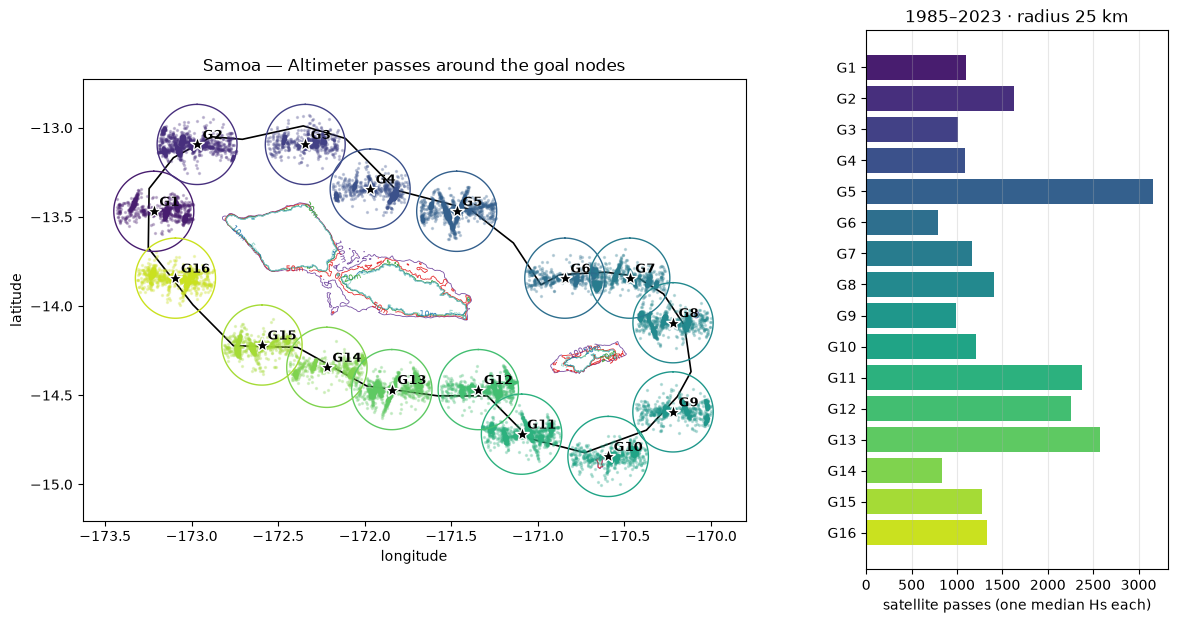

In [4]:
fig = viz.plot_satellite_pairs(pairs, cal.goal_nodes(offshore_name), cfg["radius_km"])

## 2. Calibration per goal

Fitted on `train_fraction` of each goal's passes; the metrics below are on the
**test** passes, which the fit never saw (bias = hindcast − satellite).

In [5]:
calibrations = cal.fit_calibration(offshore_name)
metrics = cal.calibration_metrics(offshore_name)
metrics[metrics["set"] == "test"].pivot(
    index="goal", columns="stage", values=["n", "bias", "rmse", "slope"]
).round(3)

n              bias              rmse             slope       
stage calibrated    raw calibrated    raw calibrated    raw calibrated    raw
goal                                                                         
1          276.0  276.0      0.151 -0.192      0.258  0.283      0.806  0.756
10         303.0  303.0      0.135 -0.098      0.252  0.232      0.827  0.827
11         594.0  594.0      0.113 -0.094      0.237  0.215      0.848  0.884
12         563.0  563.0      0.103 -0.090      0.222  0.219      0.861  0.892
13         643.0  643.0      0.054 -0.096      0.221  0.247      0.859  0.849
14         208.0  208.0      0.093 -0.043      0.244  0.222      0.841  0.824
15         319.0  319.0      0.045 -0.096      0.207  0.239      0.880  0.868
16         332.0  332.0      0.138 -0.142      0.249  0.251      0.852  0.806
2          407.0  407.0      0.131 -0.126      0.266  0.252      0.819  0.740
3          252.0  252.0      0.015 -0.133      0.216  0.250      0.802  0.817
4          272.0  272.0      0.043 -0.102      0.193  0.228      0.828  0.831
5          790.0  790.0      0.050 -0.150      0.191  0.237      0.884  0.876
6          198.0  198.0      0.155 -0.060      0.268  0.219      0.753  0.790
7          292.0  292.0      0.049 -0.138      0.371  0.384      0.521  0.586
8          352.0  352.0      0.119 -0.152      0.248  0.257      0.804  0.807
9          247.0  247.0      0.149 -0.089      0.256  0.209      0.863  0.847

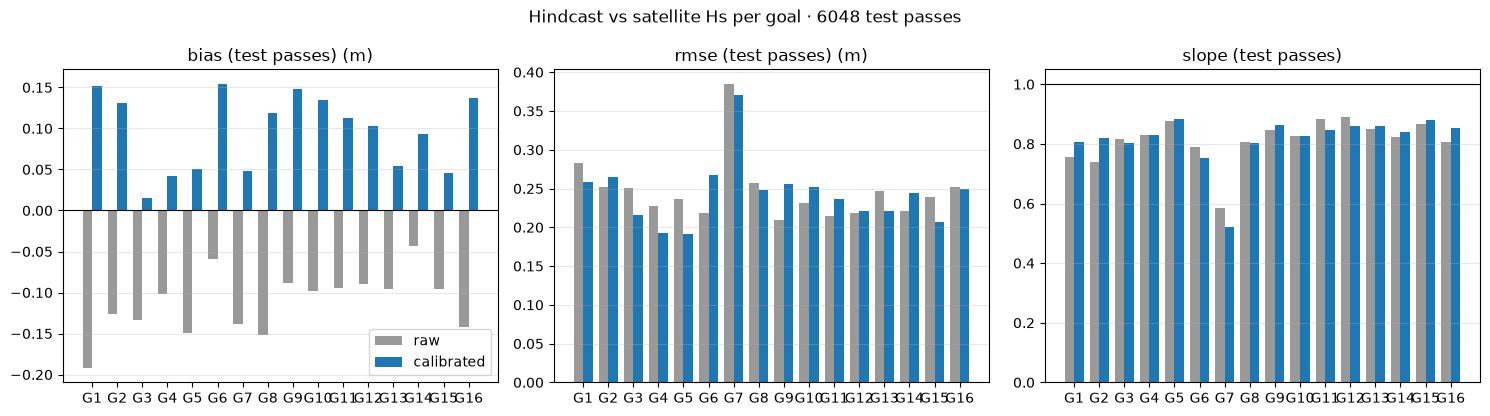

In [6]:
fig = viz.plot_calibration_metrics(metrics, subset="test")

Per goal: test passes before and after the calibration, and the Hs factor of
each direction sector for wind sea and swell (red above 1, blue below, grey =
not enough data, left at 1).

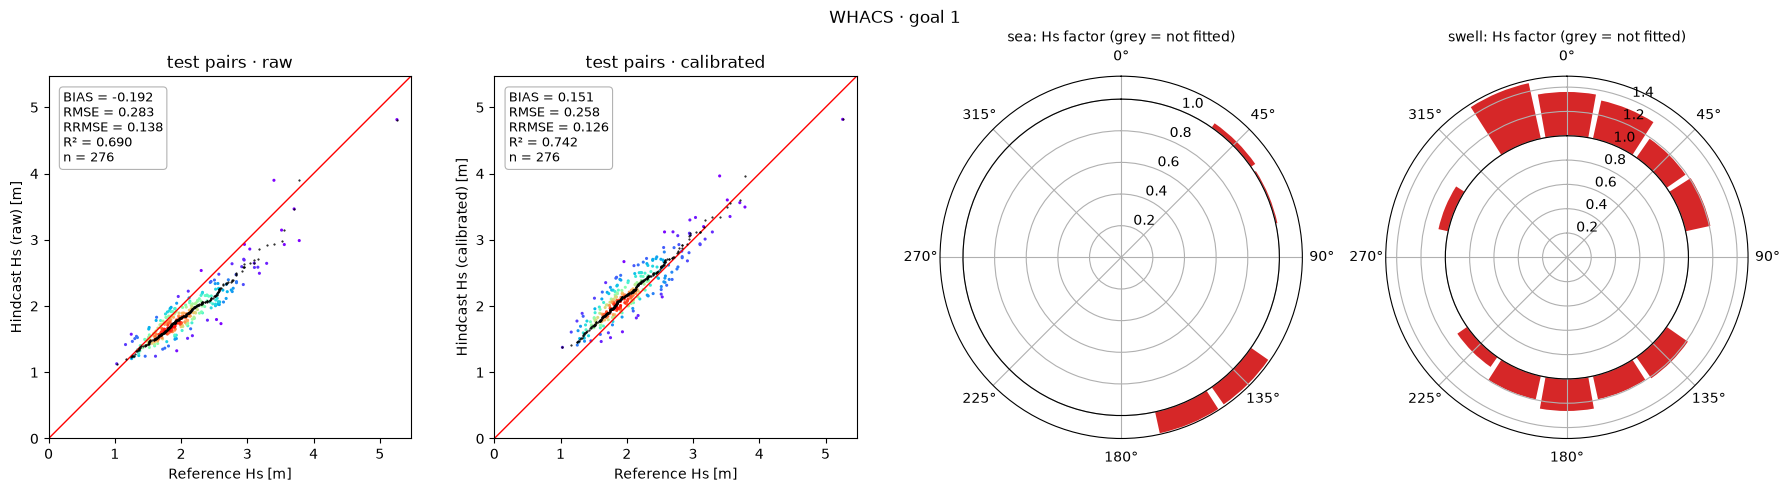

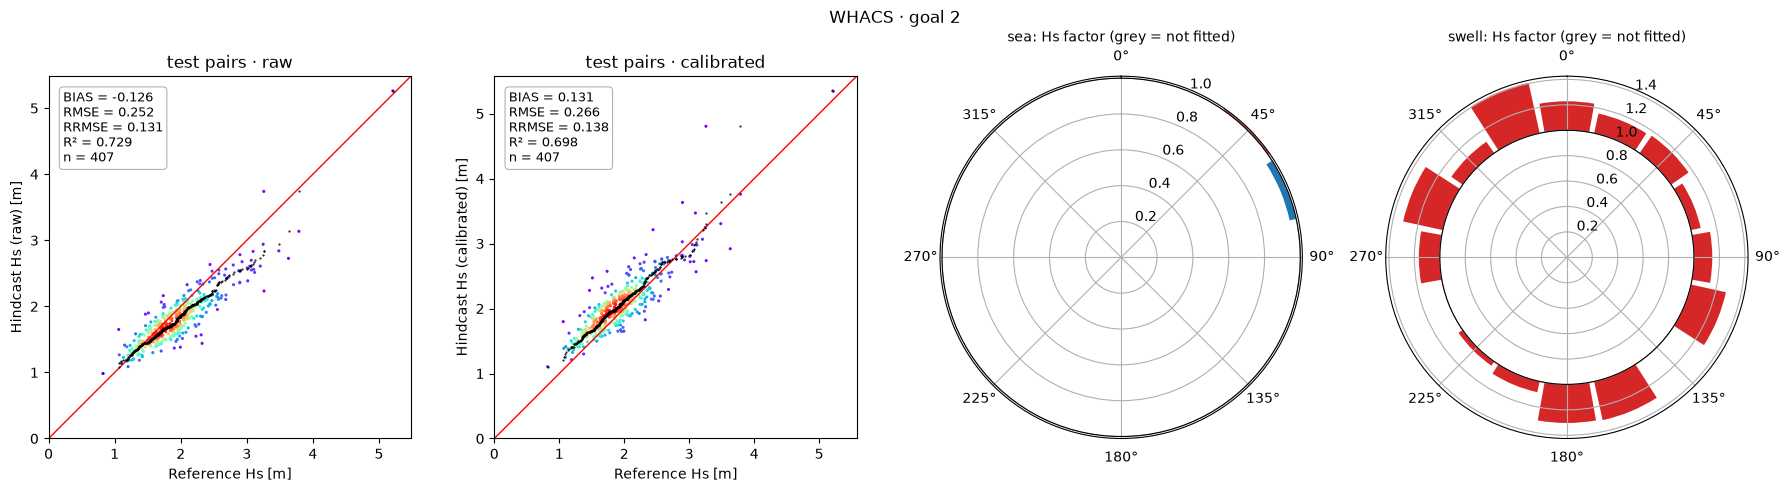

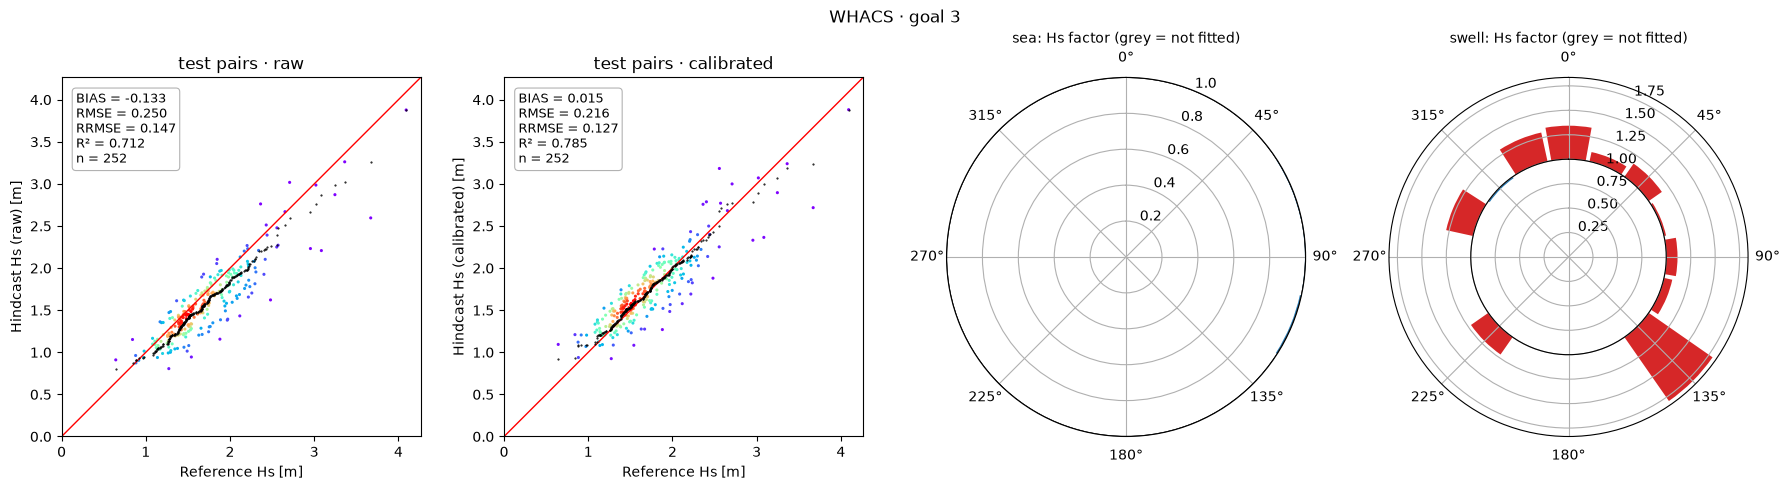

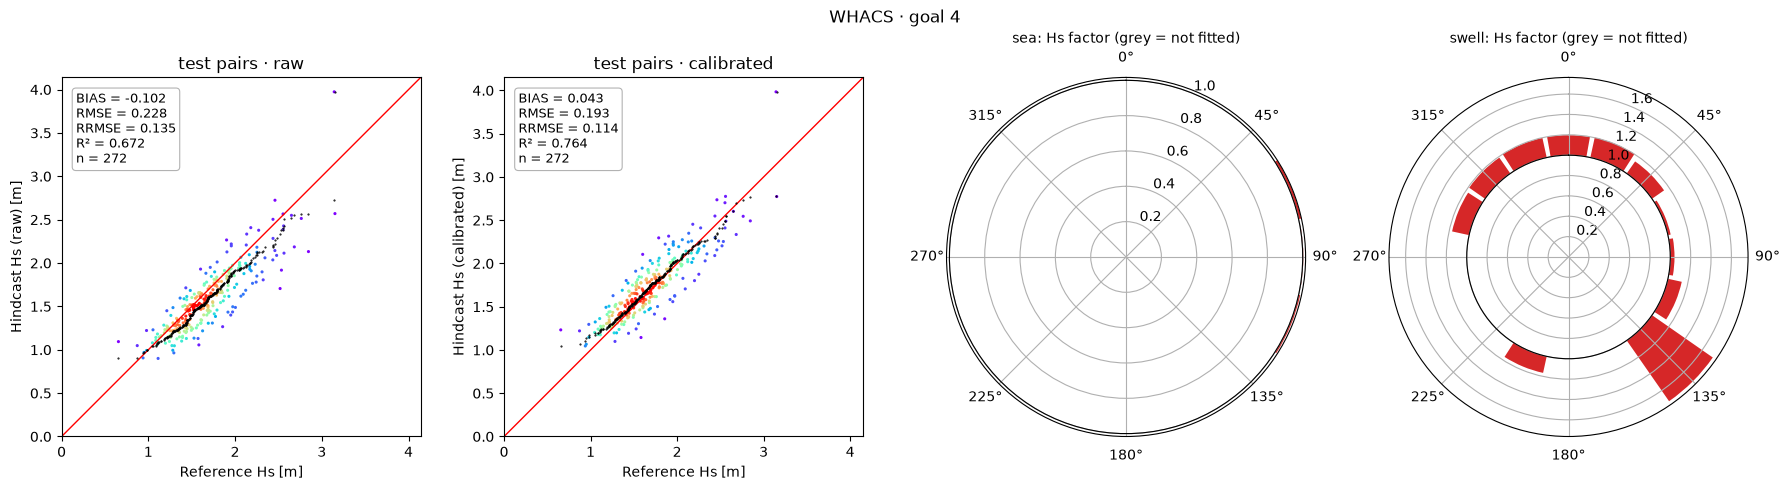

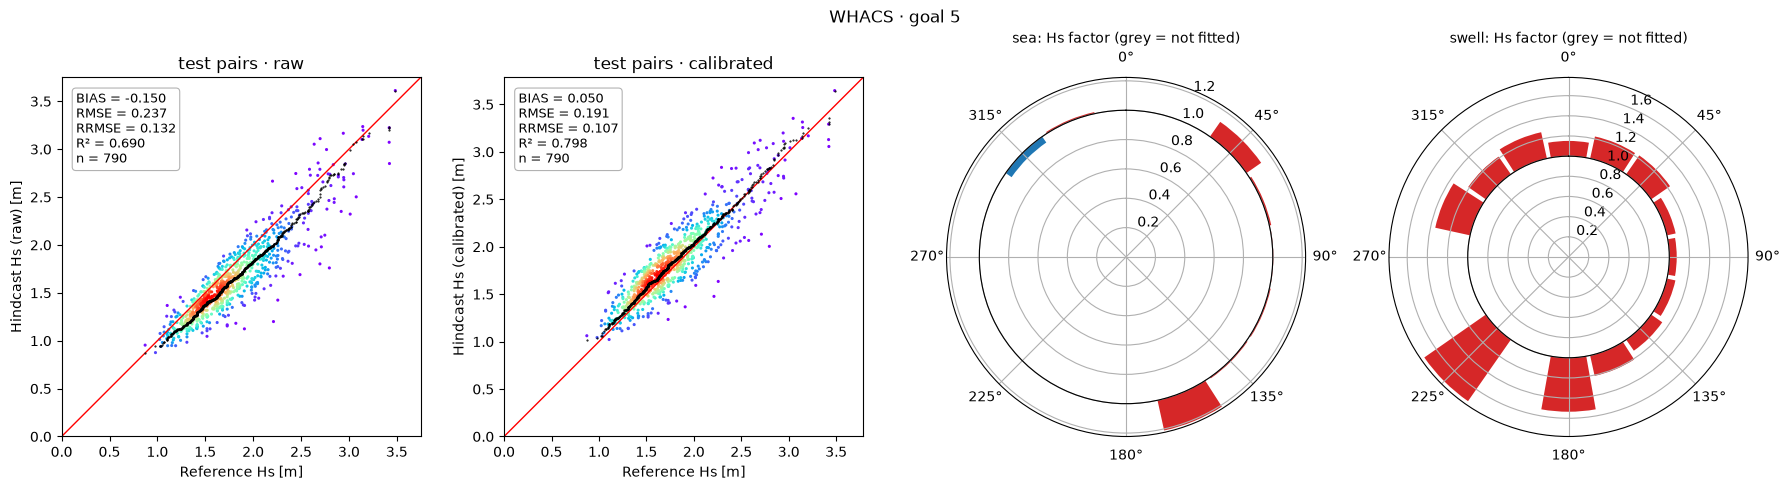

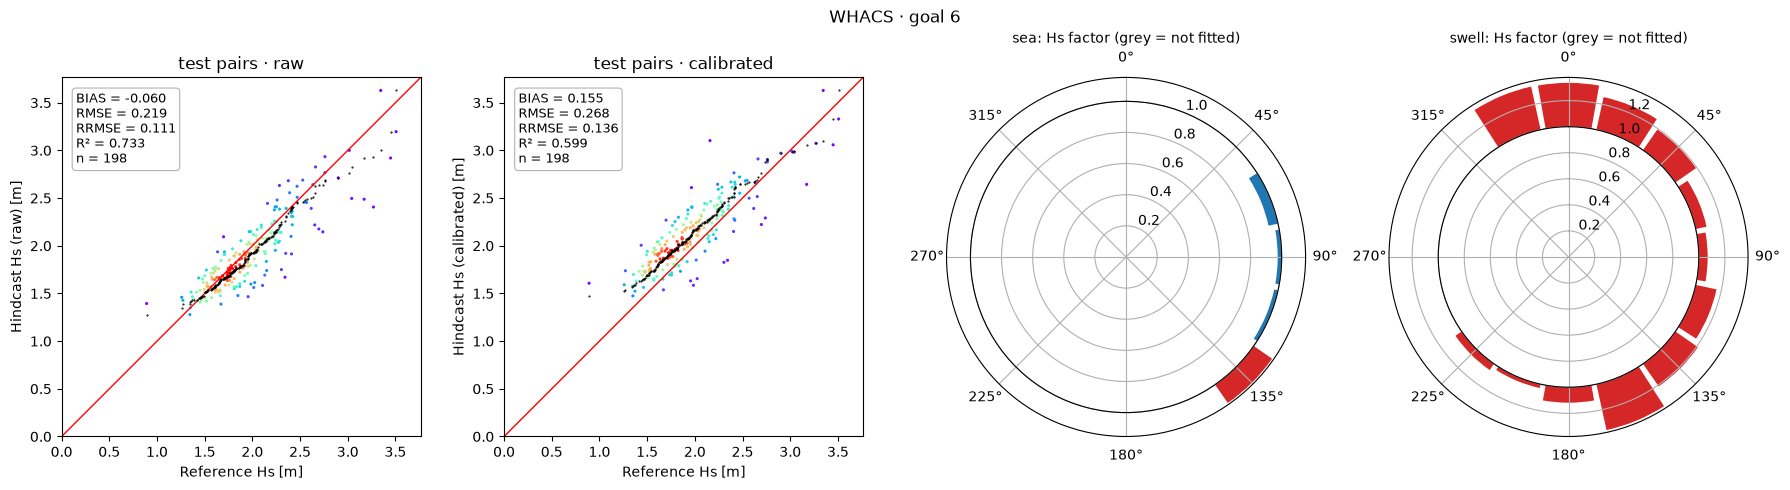

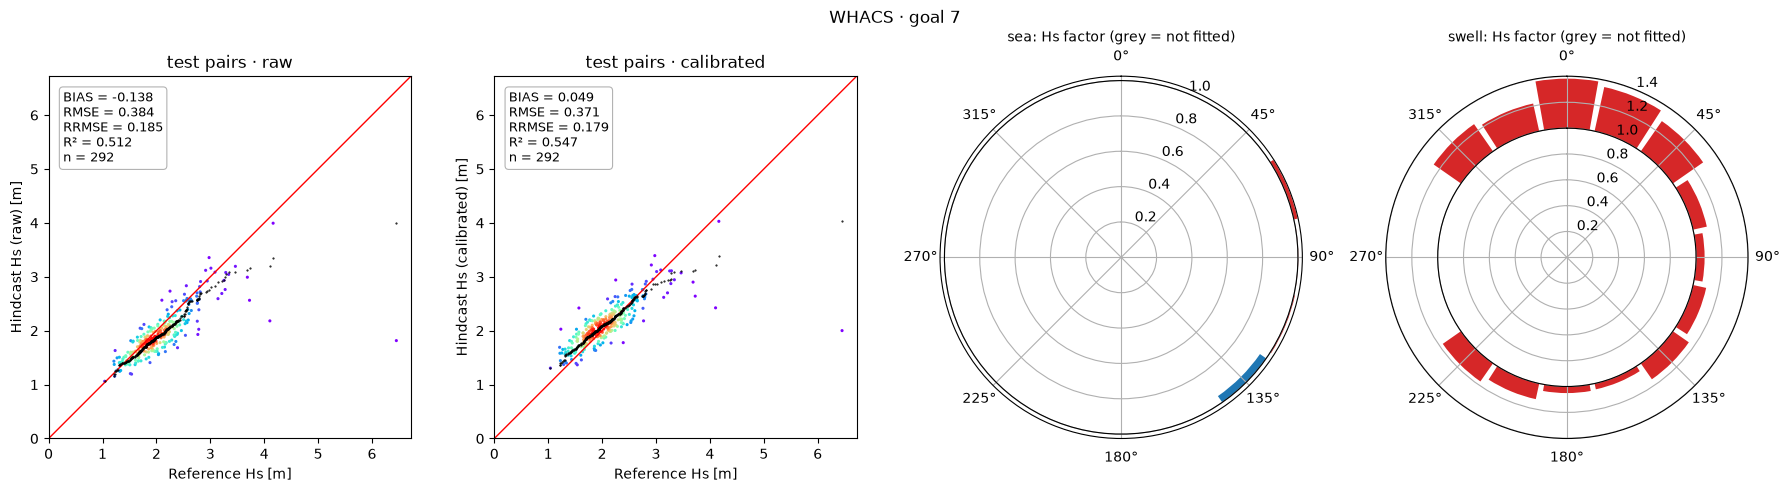

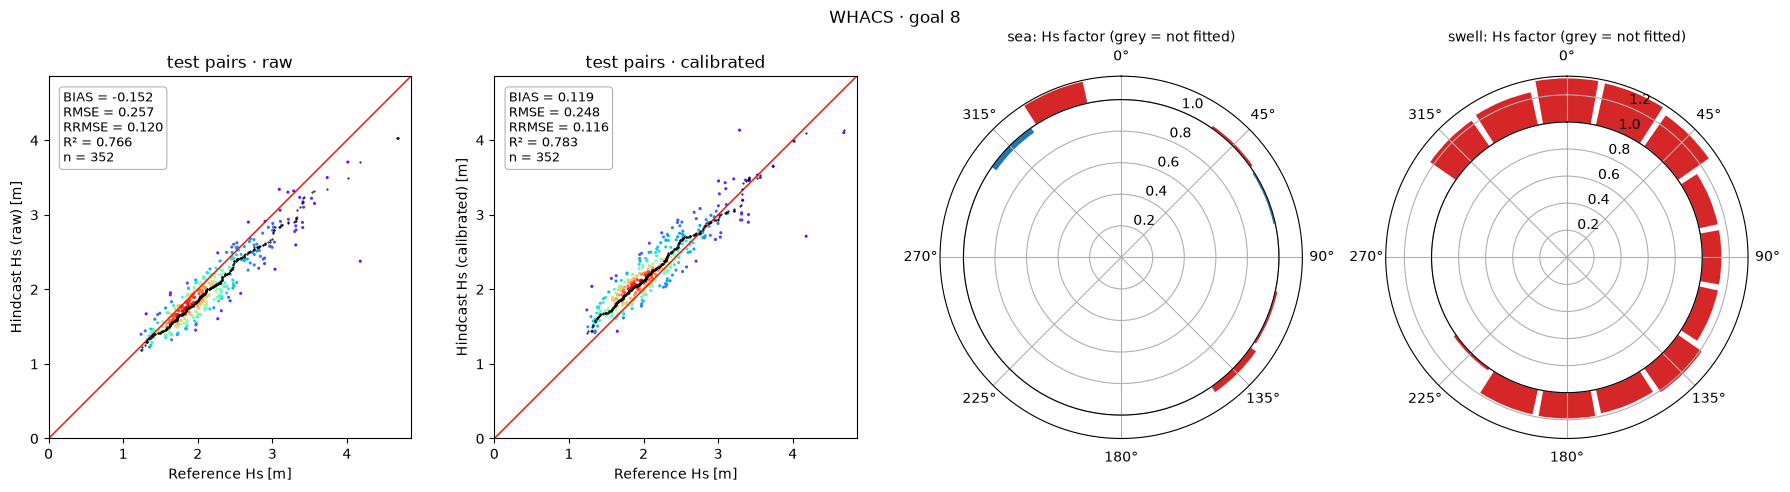

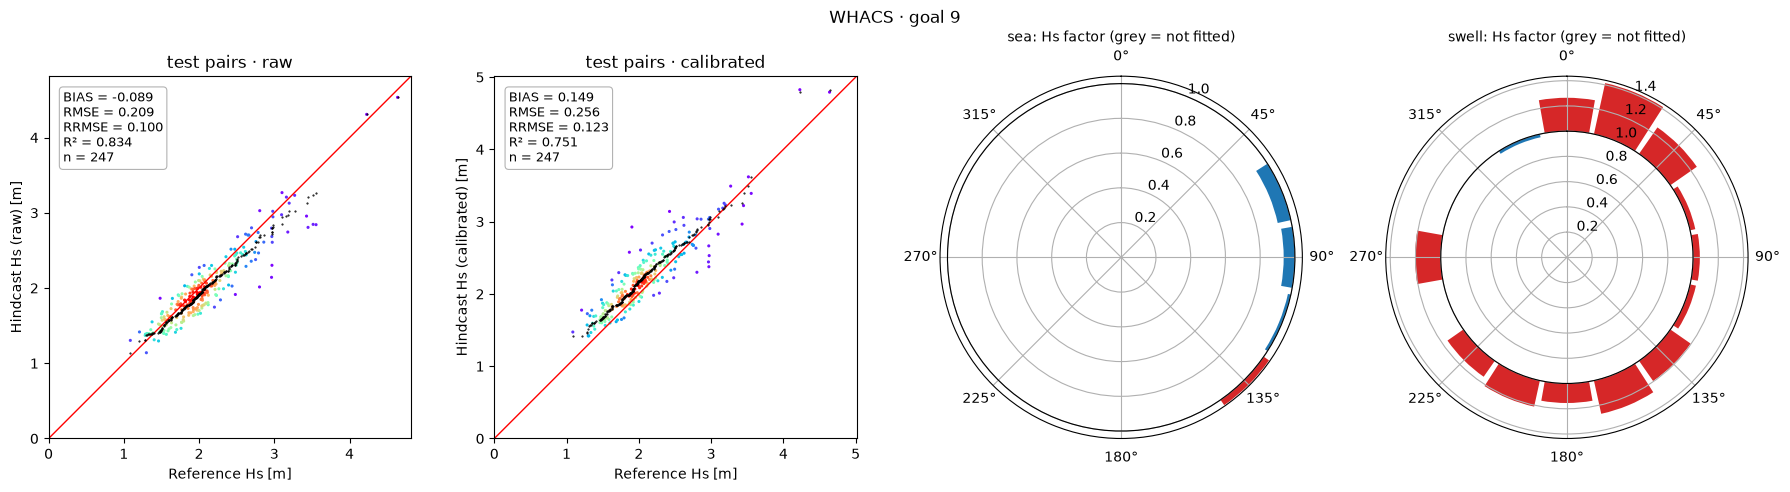

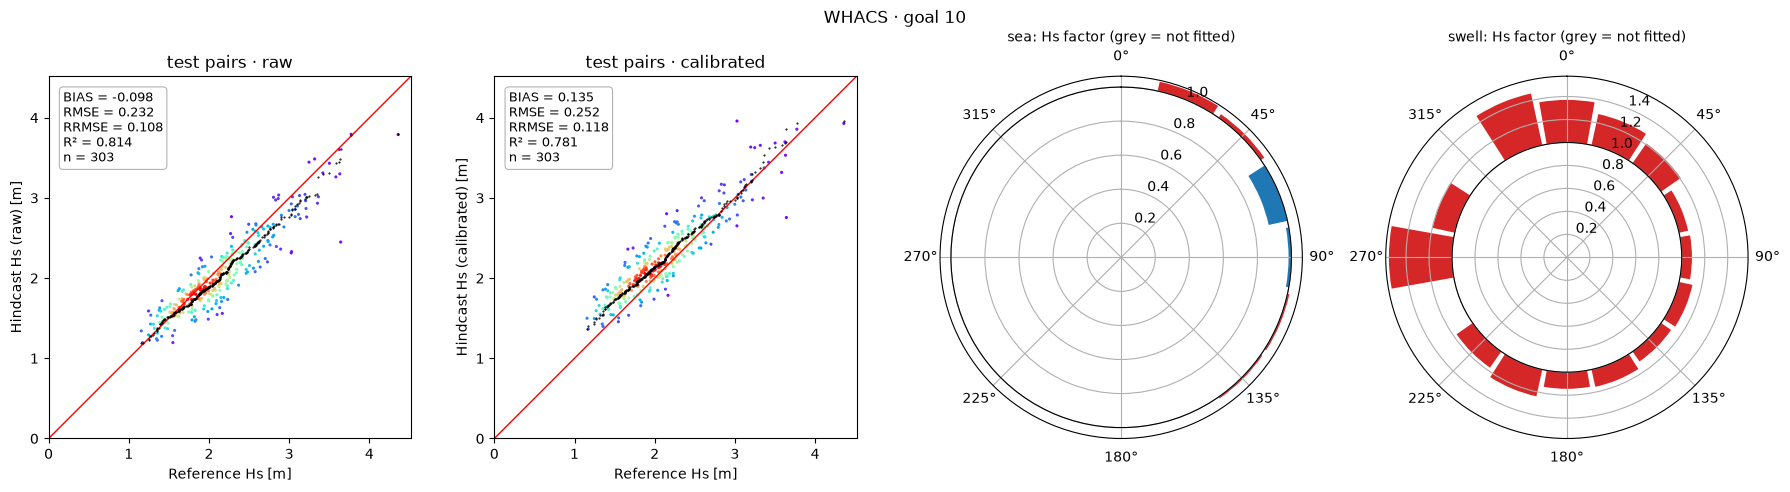

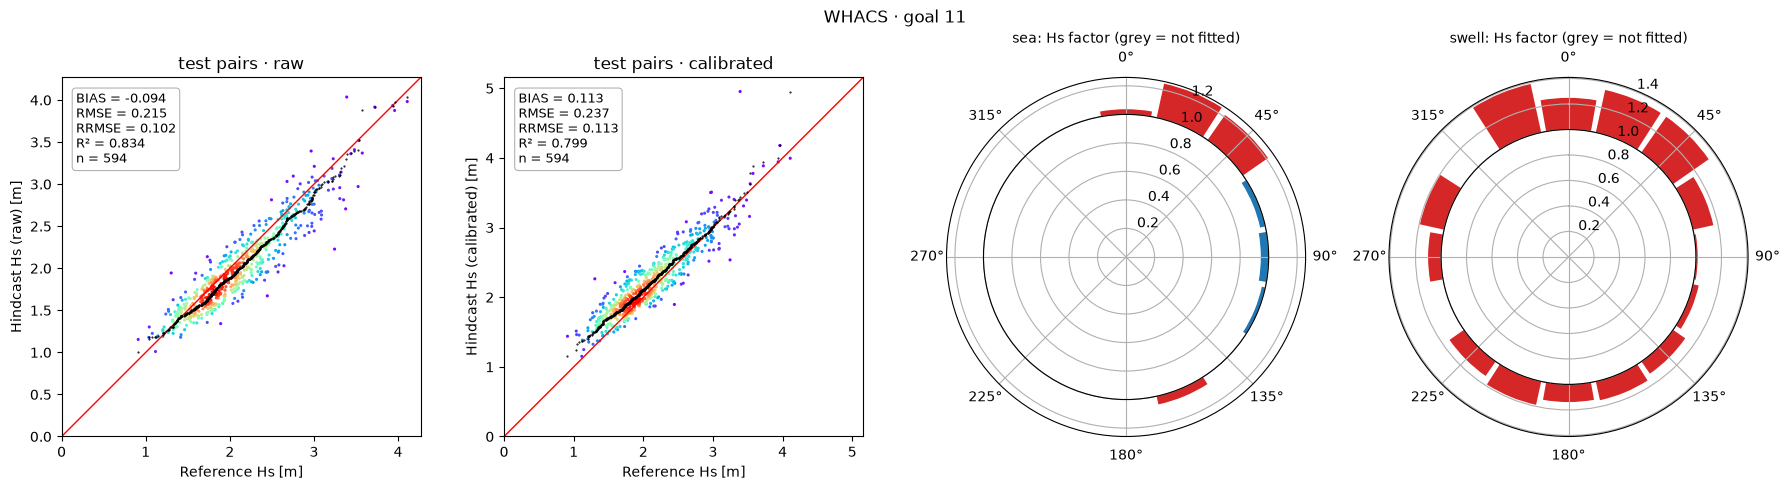

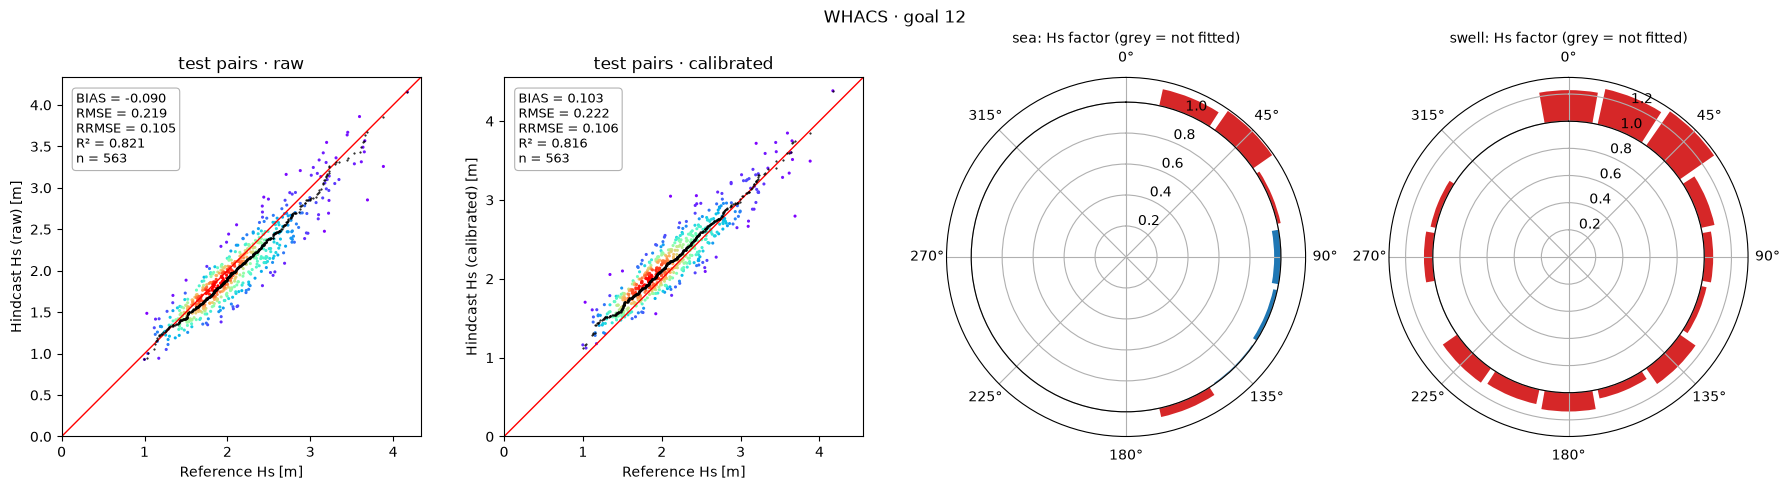

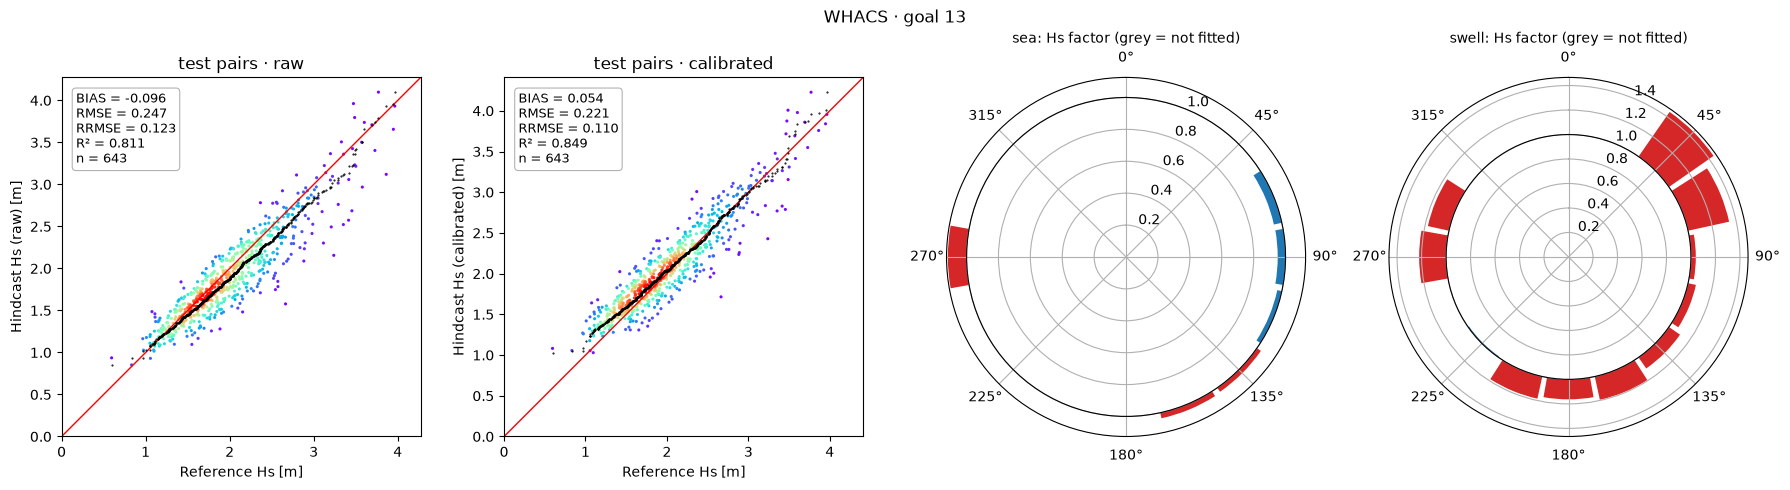

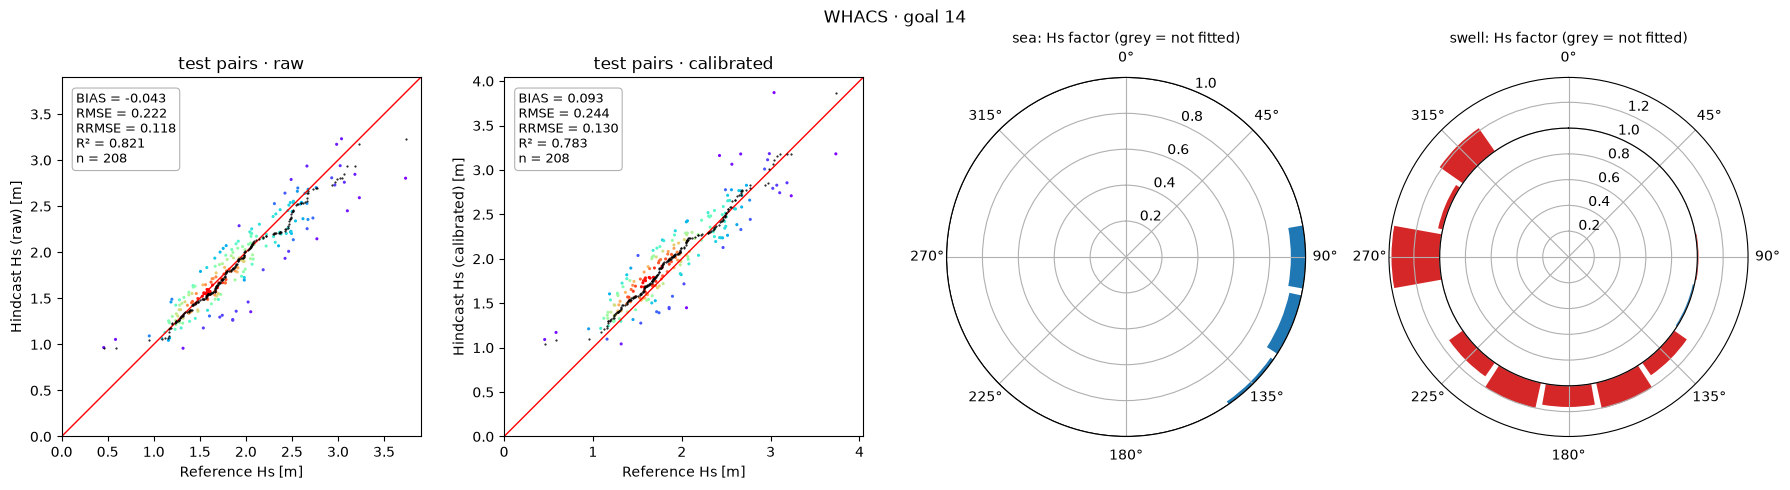

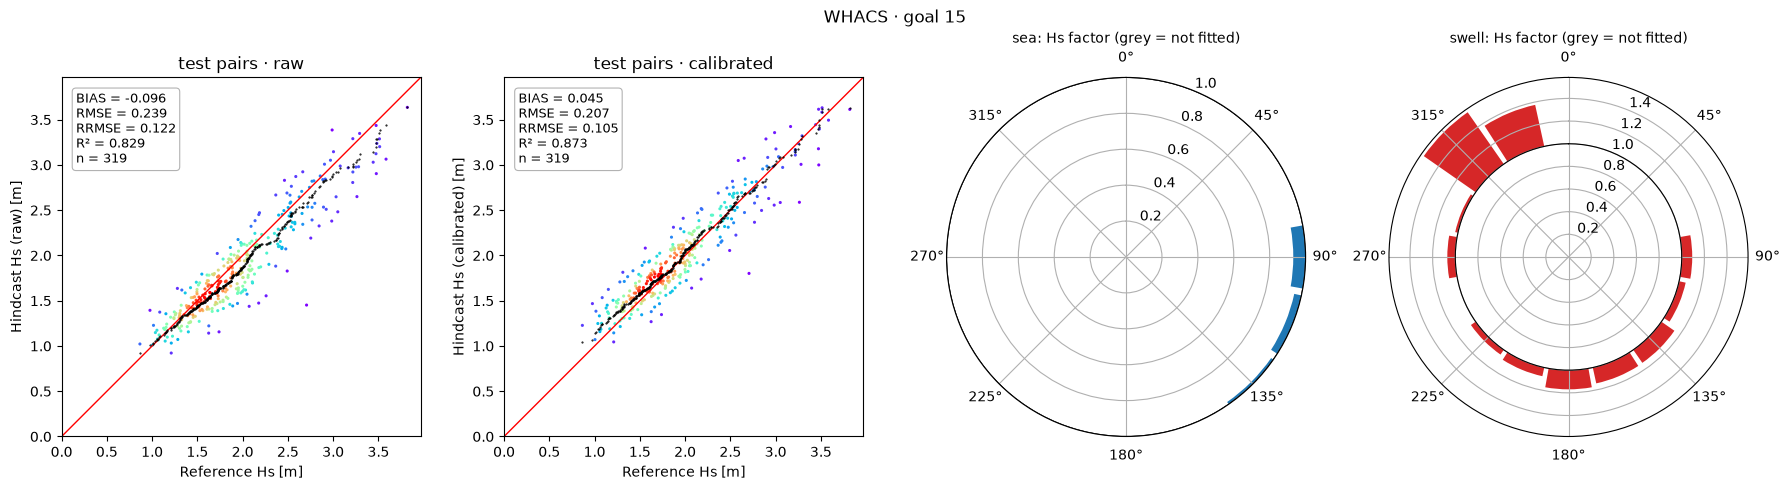

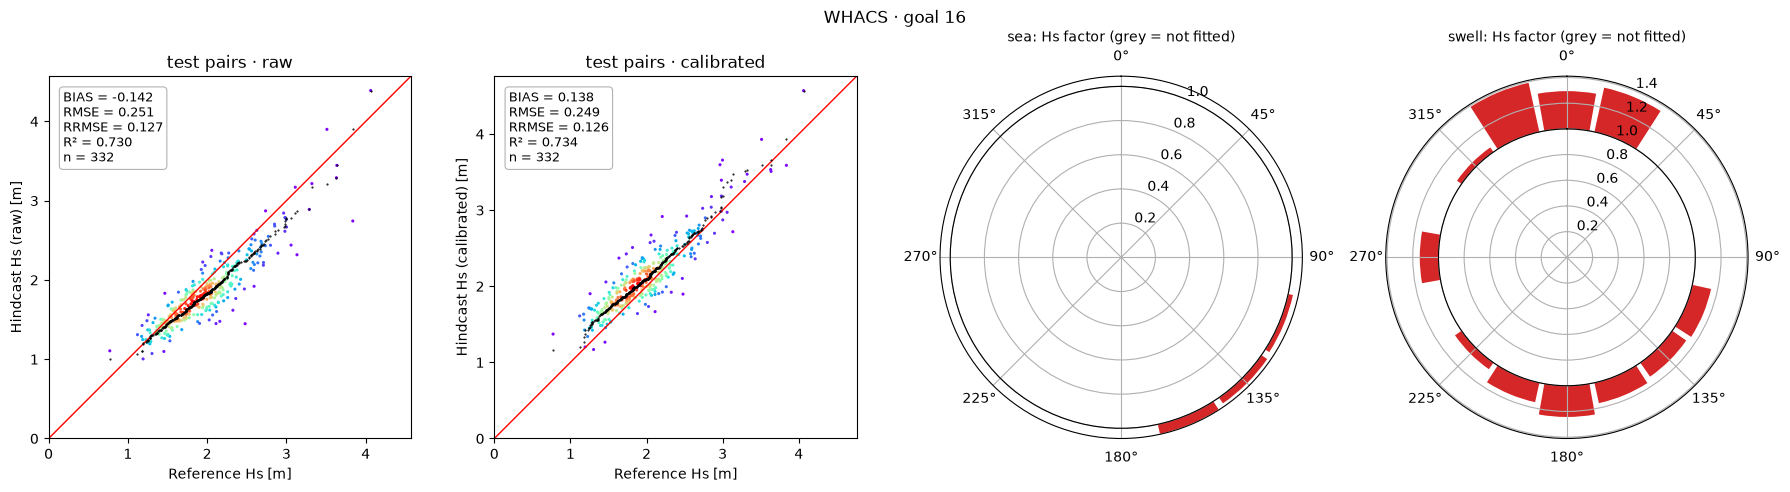

In [7]:
for gid, calval in calibrations.items():
    calval.plot(title=f"{offshore_name} · goal {gid}")

## 3. Storm tail: quantile mapping

A factor per sector fixes the level, not a tail that is too short: storms need
more than calm seas. One quantile map over the passes of **all** goals (one goal
has too few storm passes) brings the directionally calibrated Hs to the
altimeter distribution, with a constant offset beyond `tail_quantile` (default
0.999), where the quantiles rest on a handful of passes.

The table gives the Hs of the satellite and of each stage (`raw`, `hindcast` =
after the directional step, `mapped`) at a few probabilities; `n_above` is how
many passes the value rests on.

**Fitted on all the passes** (train and test of section 2), so everything in
this section is in-sample: the buoys in `10_Validate_Buoys` are the independent
check.

**Per-goal maps are possible too** (one `QuantileMapping` per goal on its own
passes, tail quantile `1 - 6 / n` so at least 6 passes sit above it). Where
goals have many passes, per-goal maps fix the body of each goal's distribution
better (smaller bias between goals), but each tail rests on a handful of passes,
so the storm tail gets noisier and can overshoot. Pooled is the default; a
hybrid (per-goal body, pooled tail) is the middle way if goals disagree.

In [8]:
mapping = cal.fit_quantile_mapping(offshore_name)
qm_pairs = cal.quantile_mapping_pairs(offshore_name)
mapping.quantiles(raw=qm_pairs["hs_raw"].to_numpy()).round(2)

,reference,raw,hindcast,mapped,n_above
probability,,,,,
0.500,1.92,1.79,2.01,1.92,12094
0.900,2.68,2.50,2.71,2.68,2419
0.990,3.63,3.44,3.65,3.63,242
0.999,4.65,4.46,4.73,4.65,24


How to read the four panels:

- **(a) the map**: the correction added to the directional Hs, as a function of
  it. Below the first fitted quantile (p1) it is a factor, between the fitted
  quantiles (dots) a linear interpolation, beyond `tail_quantile` a constant
  offset: every storm above it gets the same extra metres, set by the few
  passes counted in the red band. The grey histogram shows how many passes
  support each part of the curve.
- **(b) Q-Q**: hindcast quantiles against satellite quantiles; on the 1:1 line
  the two distributions agree. The directional step moves the level, the map
  bends the tail.
- **(c) tail**: the same on an exceedance-probability (log) axis, where the
  storms are visible.
- **(d) pairs**: mapped Hs of each pass against its satellite Hs. The map
  matches distributions, not passes: compare the RMSE with the directional
  step in section 2.

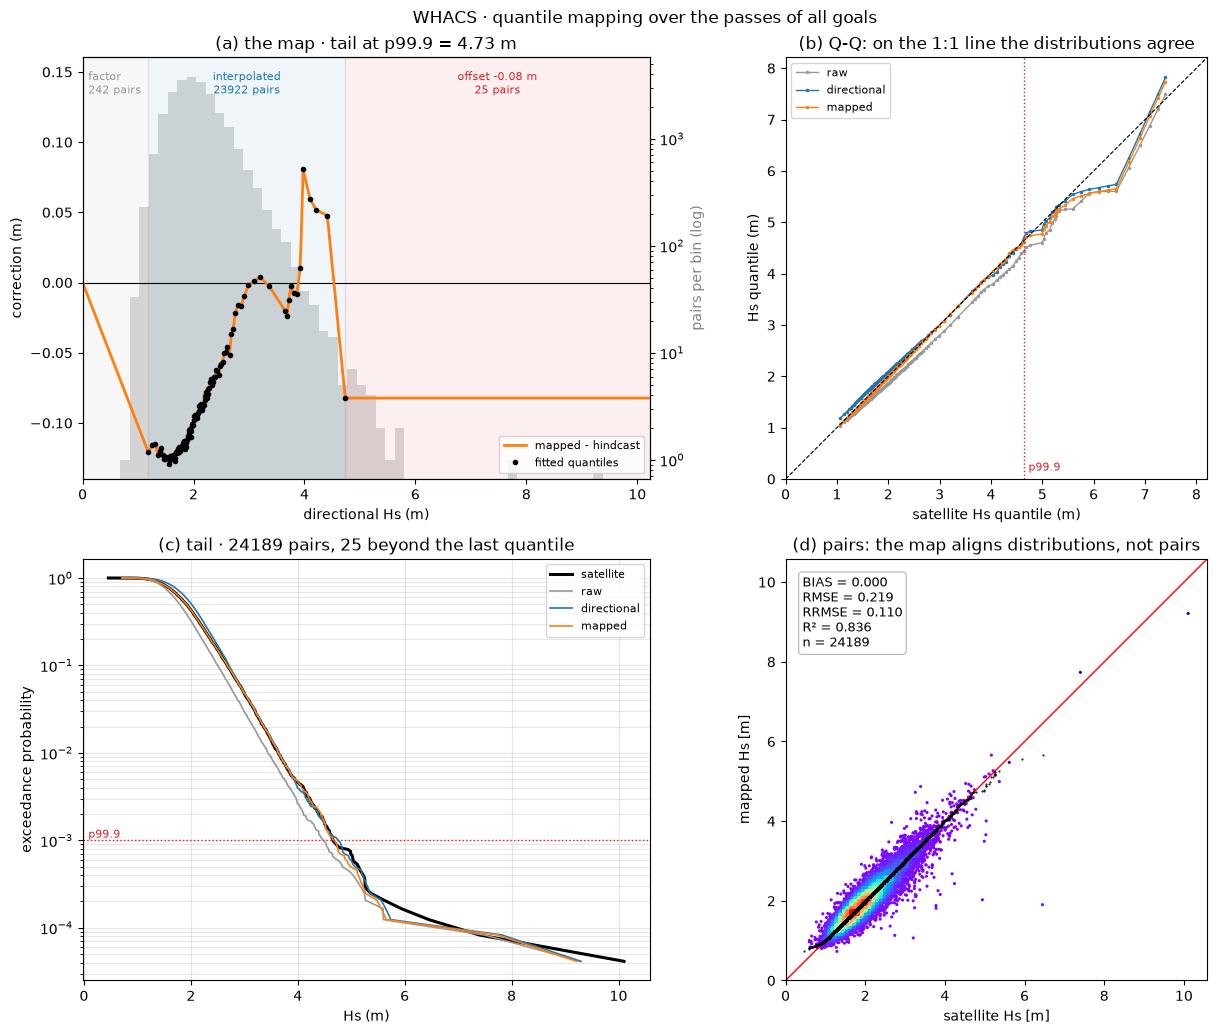

In [9]:
fig = mapping.plot(
    raw=qm_pairs["hs_raw"].to_numpy(),
    labels={"reference": "satellite", "hindcast": "directional"},
    title=f"{offshore_name} · quantile mapping over the passes of all goals",
)

**One map for all goals: does it fit each one?** Hs quantile error (hindcast −
satellite) per goal for the three stages. Near zero for `mapped` at every goal
means one pooled map is enough; a goal that stays off at p90 has a different
tail. At p99 each goal has only ~10–30 passes above, so expect noise there.

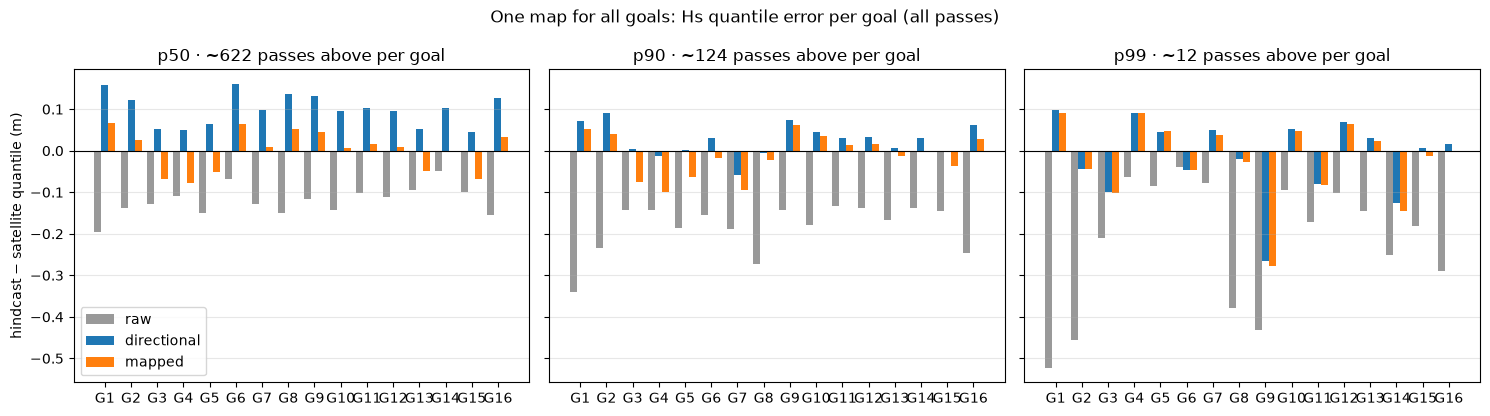

In [10]:
fig = viz.plot_quantile_mapping_goals(qm_pairs, mapping)

## 4. Write the calibrated hindcast

Applies each goal's factors and the tail map to the whole record (partition Hs
times its sector factor, bulk Hs rescaled, then both by the tail ratio; periods
and directions unchanged) and writes
`*_cal.zarr` next to the source. Add the printed entry to `offshore_waves` in
the case JSON.

In [11]:
entry = cal.write_calibrated_hindcast(offshore_name)
print(json.dumps(entry, indent=4))

{
    "name": "WHACS_cal",
    "data_path": "inputs/WHACS/processed/Samoa_WHACS_goal_cal.zarr",
    "hindcast": "WHACS"
}


**What the calibration does to the whole record**: exceedance curves of the full
hourly series at each goal, raw and calibrated, with the satellite passes. In
the grey band (rarer than one pass) no satellite checks the record: there the
calibrated tail is the shape of the hindcast tail plus the constant offset.

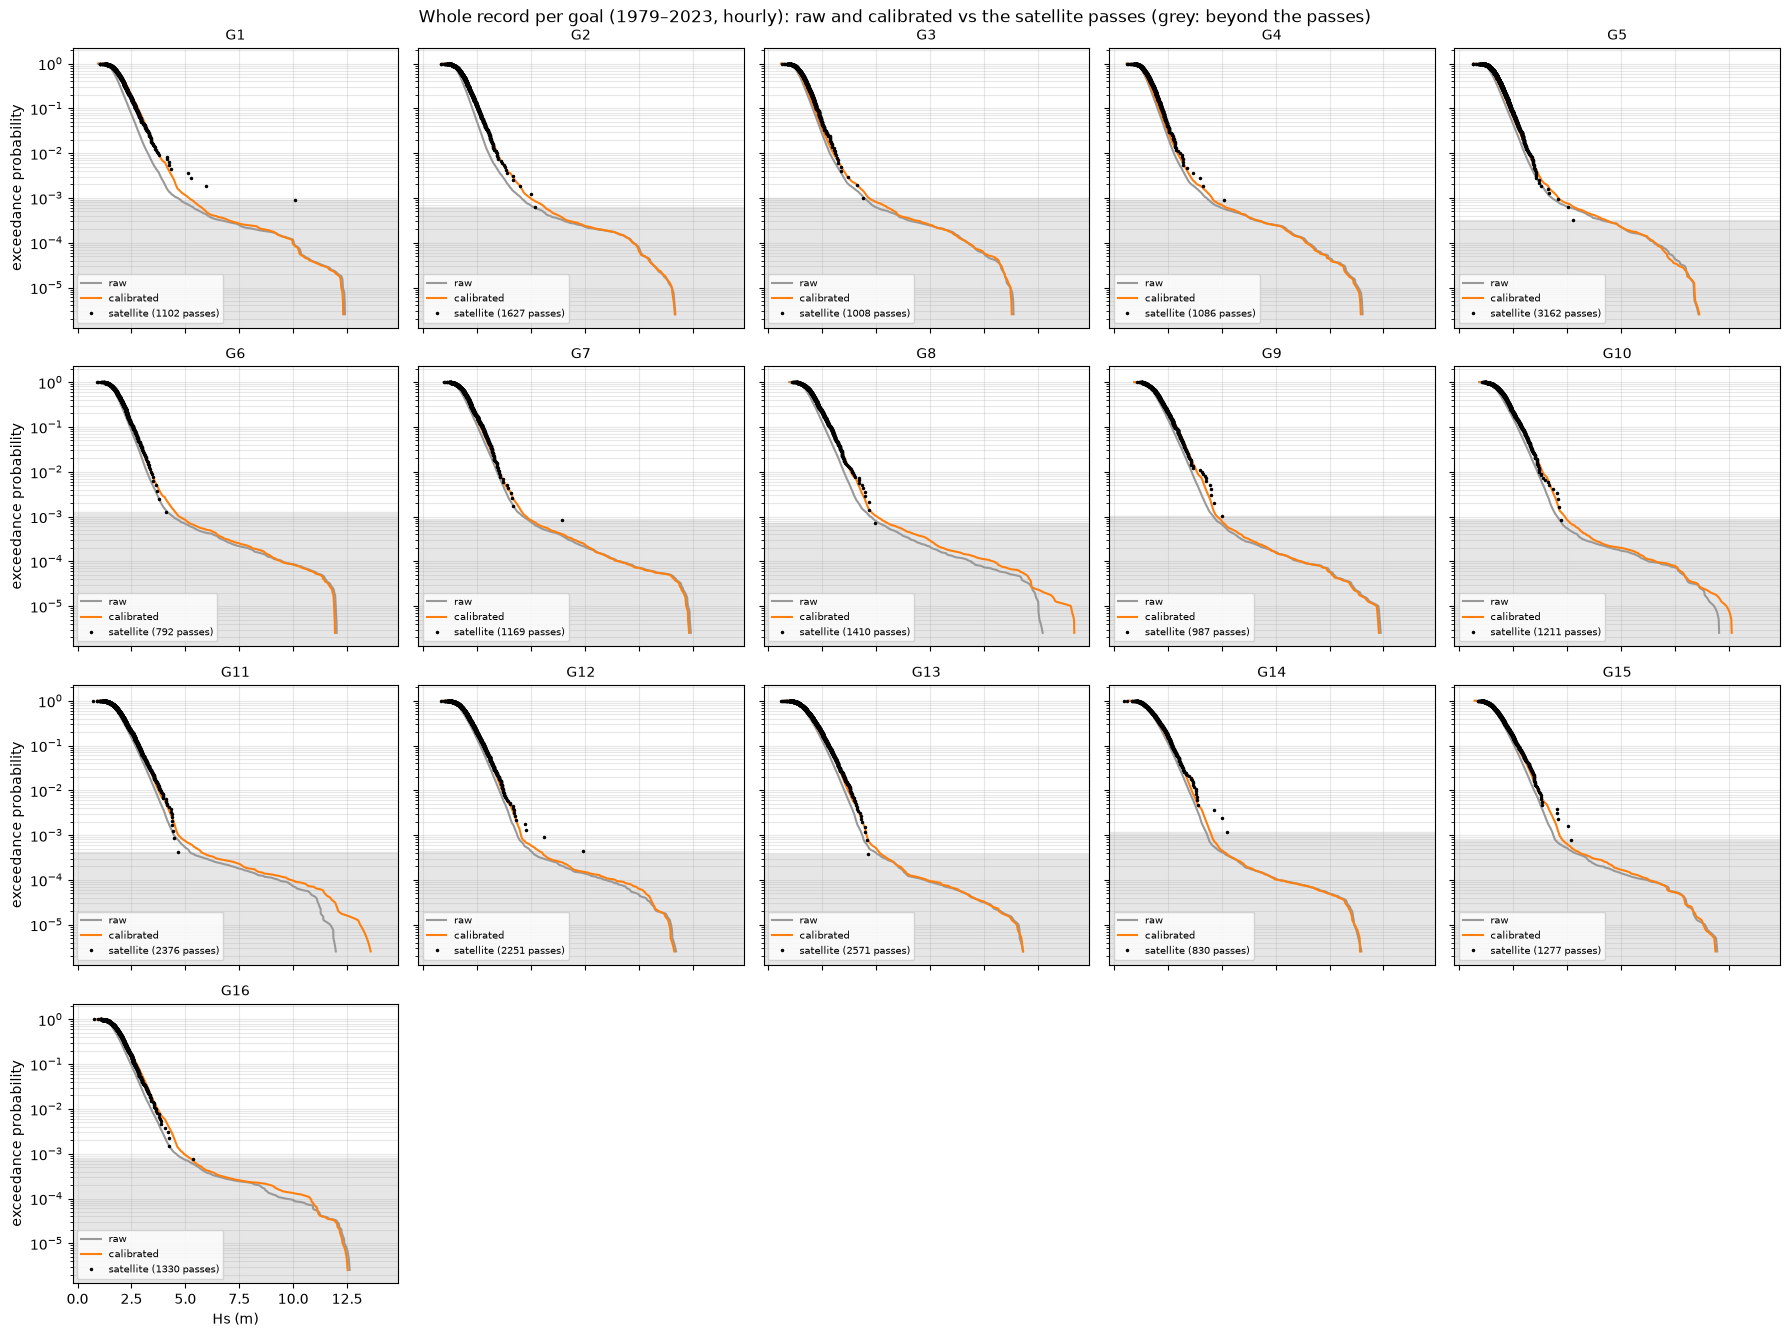

In [12]:
raw_hs = open_offshore_waves(offshore_name)["hs"].load()
calibrated_hs = open_offshore_waves(entry=entry)["hs"].load()
fig = viz.plot_calibrated_record(raw_hs, calibrated_hs, pairs)

## 5. Independent check: deep buoys near the goals

The satellite fitted both steps; the buoys did not. Buoys deeper than
`buoy_min_depth` and within `buoy_max_distance_km` of their closest goal node
measure nearly the same sea as the hindcast node, so raw and calibrated Hs there
(closest goal, no propagation) show whether the calibration helps. Metrics on
the hours both have (bias = hindcast − buoy); `q{p}` is the error at that Hs
quantile, the tail check (do not bin errors by observed Hs: regression to the
mean overstates the storm bias).

In [13]:
buoy_max_distance_km = 50  # to the closest goal node
buoy_min_depth = 24  # m, mesh depth at the buoy

buoy_sites = cal.buoy_check_sites(offshore_name, max_distance_km=buoy_max_distance_km, min_depth=buoy_min_depth)
buoy_sites.round(1)

,site,goal,distance_km,depth
0,buoy_Aunuu_1,8,35.2,74.5
1,buoy_Aunuu_2,8,36.3,55.8


In [14]:
buoy_hs, buoy_estimates = cal.buoy_check(offshore_name, entry, buoy_sites)
buoy_metrics = cal.buoy_check_metrics(buoy_hs, buoy_estimates)
buoy_metrics.groupby("estimate")[["bias", "rmse", "r2", "q50", "q99", "q99.9"]].median().round(3)

,bias,rmse,r2,q50,q99,q99.9
estimate,,,,,,
WHACS,-0.148,0.243,0.782,-0.144,-0.251,0.238
WHACS_cal,0.055,0.233,0.800,0.053,-0.009,0.349


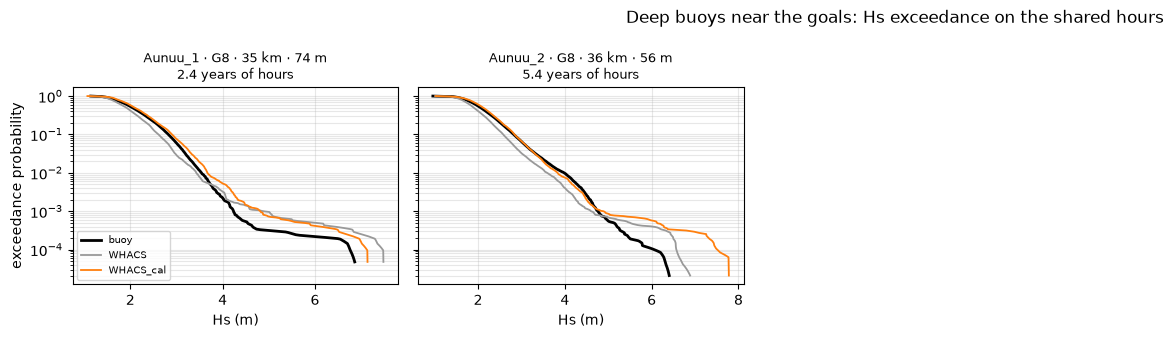

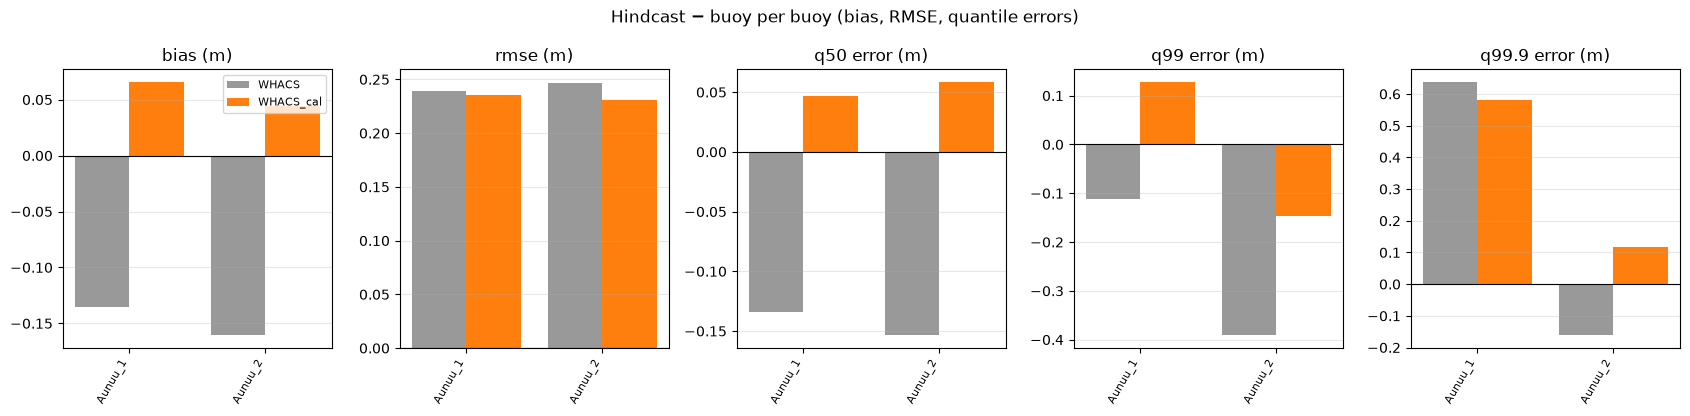

In [15]:
figs = viz.plot_buoy_check(buoy_hs, buoy_estimates, buoy_sites, buoy_metrics)

## Next

- Add the entry above to `offshore_waves` in the case JSON.
- `08_Dynamic_Cases_Generation.ipynb` with `offshore_name = "WHACS_cal"` (the
  dynamic runs must be forced with the calibrated hindcast too, so that 09
  compares like with like), then 09–12 with the same name.
- `10_Validate_Buoys.ipynb` with both names: the buoys are an independent check
  of the calibration.